# Imputación de PM10 con Random Forest, covariables meteorológicas y tratamiento de atípicos

Este notebook fue corregido nuevamente (V3) para realizar **imputación multivariable con Random Forest** usando covariables meteorológicas y, adicionalmente, detectar e imputar **valores atípicos** del contaminante objetivo.

El flujo metodológico incluye:

1. lectura robusta de archivos;
2. reconstrucción de la serie diaria completa por estación;
3. detección de faltantes reales;
4. detección de valores atípicos mediante criterios robustos;
5. conversión de faltantes y atípicos en valores a imputar;
6. construcción de variables temporales, rezagos y medias móviles;
7. validación ocultando datos conocidos;
8. imputación final con Random Forest;
9. generación de tablas, gráficas y archivos finales.

> Recomendación: reinicia el kernel y ejecuta todo en orden.

**Actualización V3:** se agregó exportación explícita del dataset final limpio y del dataset final con trazabilidad.

**Actualización:** se agregó medición del tiempo total de ejecución del notebook y exportación del CSV con el tiempo en la carpeta principal del Jupyter.

In [20]:
# ============================================================
# INICIO DE MEDICIÓN DEL TIEMPO TOTAL DEL NOTEBOOK
# ============================================================

import time
from datetime import datetime

TIEMPO_INICIO_NOTEBOOK = time.perf_counter()
FECHA_HORA_INICIO_NOTEBOOK = datetime.now()

print("Inicio de ejecución del notebook:")
print(FECHA_HORA_INICIO_NOTEBOOK.strftime("%Y-%m-%d %H:%M:%S"))

Inicio de ejecución del notebook:
2026-07-10 21:39:43


## 1. Librerías y configuración general

In [21]:
# Si necesitas instalar dependencias, descomenta:
# !pip install openpyxl xlrd

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from IPython.display import display, Markdown

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 250)
pd.set_option("display.width", 250)

# ============================================================
# CONFIGURACIÓN PRINCIPAL
# ============================================================
TARGET = "PM10"
TARGET_ALIASES = ['PM10', 'pm10', 'PM 10']

SEED = 42
np.random.seed(SEED)

# Ruta manual opcional. Si los archivos están en la misma carpeta del notebook, deja None.
# Ejemplo Windows: BASE_MANUAL = Path(r"C:\Users\Usuario\Datos")
BASE_MANUAL = None
BASE = Path(BASE_MANUAL) if BASE_MANUAL is not None else Path.cwd()

# En ChatGPT los archivos suelen estar en /mnt/data. En tu PC se usará la carpeta del notebook.
RUTAS_BUSQUEDA = [BASE]
if Path("/mnt/data").exists() and Path("/mnt/data") not in RUTAS_BUSQUEDA:
    RUTAS_BUSQUEDA.append(Path("/mnt/data"))

OUTPUT_DIR = BASE / "salidas_PM10_RF_con_atipicos"
GRAF_DIR = OUTPUT_DIR / "graficas"
TABLAS_DIR = OUTPUT_DIR / "tablas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
GRAF_DIR.mkdir(parents=True, exist_ok=True)
TABLAS_DIR.mkdir(parents=True, exist_ok=True)

# Covariables meteorológicas usadas por el modelo.
COVARIABLES = ["DViento", "VViento", "HAire2", "TAire2"]

# ============================================================
# CONFIGURACIÓN DE DETECCIÓN DE ATÍPICOS
# ============================================================
DETECTAR_ATIPICOS = True
IMPUTAR_ATIPICOS = True

# Método robusto principal: mediana móvil + MAD.
VENTANA_ROLLING_ATIPICOS = 15
UMBRAL_Z_ROBUSTO = 3.5

# Criterio IQR por estación como apoyo.
MULTIPLICADOR_IQR = 1.5

# Para evitar marcar picos reales por un solo criterio, el valor se marca atípico si:
# - es negativo; o
# - cumple simultáneamente criterio MAD y criterio IQR.
# Si quieres una detección más agresiva, cambia a "MAD_O_IQR".
CRITERIO_COMBINACION_ATIPICOS = "MAD_E_IQR"  # opciones: "MAD_E_IQR", "MAD_O_IQR"

# ============================================================
# CONFIGURACIÓN DEL RANDOM FOREST
# ============================================================
MODELO_RF = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features=0.8,
    bootstrap=True,
    random_state=SEED,
    n_jobs=-1,
    oob_score=True
)

# Porcentaje de datos conocidos que se ocultarán para validar la imputación.
FRACCION_VALIDACION_OCULTA = 0.15
MAX_REGISTROS_VALIDACION = 120
MIN_DATOS_ENTRENAMIENTO = 30

print("Carpeta base:", BASE)
print("Rutas de búsqueda:", RUTAS_BUSQUEDA)
print("Carpeta de salida:", OUTPUT_DIR)

Carpeta base: C:\Users\santi\Bogota_Version_2
Rutas de búsqueda: [WindowsPath('C:/Users/santi/Bogota_Version_2')]
Carpeta de salida: C:\Users\santi\Bogota_Version_2\salidas_PM10_RF_con_atipicos


## 2. Funciones auxiliares para localizar y leer archivos

In [22]:
# ============================================================
# PATRONES DE ARCHIVOS
# ============================================================
PATRONES_ARCHIVOS = {
    "TARGET": (
        ["PM10_dataset_completo.csv", "PM10_dataset_completo*.csv", "PM10.csv", "PM10*.csv", "PM10*.xlsx", "PM10*.xls", "PM10_resultado_final*.csv"]
        if TARGET == "PM10"
        else ["PM2.5_dataset_completo.csv", "PM2.5_dataset_completo*.csv", "PM25_dataset_completo.csv", "PM25_dataset_completo*.csv", "PM2.5.csv", "PM25.csv", "PM2*.csv", "PM25*.csv", "PM2*.xlsx", "PM25*.xlsx", "PM2*.xls", "PM25*.xls", "PM25_resultado_final*.csv"]
    ),
    "DViento": ["DViento_dataset_completo_final.csv", "DViento_dataset_completo_final*.csv", "DViento*.csv", "DViento*.xlsx", "DViento*.xls"],
    "VViento": ["VViento_dataset_completo_final.csv", "VViento_dataset_completo_final*.csv", "VViento*.csv", "VViento*.xlsx", "VViento*.xls"],
    "HAire2": ["HAire2_dataset_completo_final.csv", "HAire2_dataset_completo_final*.csv", "HAire2*.csv", "HAire2*.xlsx", "HAire2*.xls"],
    "TAire2": ["TAire2_dataset_completo_final.csv", "TAire2_dataset_completo_final*.csv", "TAire2*.csv", "TAire2*.xlsx", "TAire2*.xls"],
}

import unicodedata
import re


def _norm_txt(x):
    """Normaliza texto para comparar nombres de columnas sin depender de tildes, espacios o mayúsculas."""
    x = str(x).replace("\ufeff", "").strip()
    x = unicodedata.normalize("NFKD", x)
    x = "".join(ch for ch in x if not unicodedata.combining(ch))
    x = x.lower()
    x = re.sub(r"[^a-z0-9]+", "", x)
    return x


def limpiar_nombre_columna(col):
    return str(col).replace("\ufeff", "").strip()


def normalizar_columnas(df):
    df = df.copy()
    df.columns = [limpiar_nombre_columna(c) for c in df.columns]
    return df


def encontrar_columna(df, candidatos, permitir_contiene=True):
    """Encuentra columna por coincidencia exacta, normalizada o parcial."""
    columnas = list(df.columns)
    candidatos = [str(c) for c in candidatos]

    for cand in candidatos:
        if cand in columnas:
            return cand

    mapa_norm = {_norm_txt(c): c for c in columnas}
    for cand in candidatos:
        key = _norm_txt(cand)
        if key in mapa_norm:
            return mapa_norm[key]

    if permitir_contiene:
        cand_norms = [_norm_txt(c) for c in candidatos]
        for col in columnas:
            coln = _norm_txt(col)
            for cand in cand_norms:
                if cand and (cand in coln or coln in cand):
                    return col

    return None


def obtener_candidatos_archivos(patrones, rutas_busqueda=RUTAS_BUSQUEDA):
    """Devuelve candidatos en el orden de prioridad de los patrones, evitando duplicados."""
    candidatos = []
    vistos = set()

    for base in rutas_busqueda:
        base = Path(base)
        for patron in patrones:
            exacto = base / patron
            if exacto.exists() and exacto.is_file():
                rp = exacto.resolve()
                if rp not in vistos:
                    candidatos.append(exacto)
                    vistos.add(rp)

            for p in sorted(base.glob(patron)):
                if p.exists() and p.is_file():
                    rp = p.resolve()
                    if rp not in vistos:
                        candidatos.append(p)
                        vistos.add(rp)

            # Búsqueda no recursiva para evitar que el notebook tarde demasiado.
            # Si tus archivos están en otra carpeta, configura BASE_MANUAL en la primera celda.

    # Evitar que el notebook lea primero salidas ya imputadas, si también existe archivo original/base.
    # Se conserva el orden de prioridad de PATRONES_ARCHIVOS.
    def penalizacion(p):
        nombre = p.name.lower()
        penal = 0
        for palabra in ["imputado", "resultado_final", "salidas", "validacion", "predicciones"]:
            if palabra in nombre:
                penal += 10
        return penal

    return [p for _, p in sorted(enumerate(candidatos), key=lambda ip: (penalizacion(ip[1]), ip[0]))]


def _detectar_fila_encabezado(df_sin_header, max_filas=30):
    """Busca una fila que parezca encabezado porque contiene fecha y/o estación."""
    max_filas = min(max_filas, len(df_sin_header))
    for i in range(max_filas):
        vals = [_norm_txt(v) for v in df_sin_header.iloc[i].tolist()]
        texto = " ".join(vals)
        tiene_fecha = any(v in texto for v in ["fechainicial", "fecha", "date"])
        tiene_estacion = any(v in texto for v in ["estacion", "station", "sitio", "punto"])
        if tiene_fecha and (tiene_estacion or True):
            return i
    return None


def leer_archivo_generico(path):
    """Lee CSV o Excel de forma robusta, incluso si el encabezado no está en la primera fila."""
    path = Path(path)
    suf = path.suffix.lower()

    def limpiar_df_leido(df):
        df = df.dropna(axis=1, how="all")
        df = df.dropna(axis=0, how="all")
        return normalizar_columnas(df)

    if suf in [".xlsx", ".xlsm", ".xltx", ".xltm", ".xls"]:
        try:
            xls = pd.ExcelFile(path)
            hoja_final = [s for s in xls.sheet_names if "final" in s.lower() or "datos" in s.lower()]
            hojas = hoja_final + [s for s in xls.sheet_names if s not in hoja_final]

            ultimo_error = None
            for hoja in hojas:
                try:
                    df = pd.read_excel(path, sheet_name=hoja)
                    df = limpiar_df_leido(df)
                    if len(df.columns) > 0:
                        return df
                except Exception as e:
                    ultimo_error = e

                try:
                    tmp = pd.read_excel(path, sheet_name=hoja, header=None)
                    fila = _detectar_fila_encabezado(tmp)
                    if fila is not None:
                        df = pd.read_excel(path, sheet_name=hoja, header=fila)
                        df = limpiar_df_leido(df)
                        return df
                except Exception as e:
                    ultimo_error = e
            if ultimo_error is not None:
                raise ultimo_error
        except Exception:
            # Algunos .xls realmente son CSV con extensión .xls
            pass

    # CSV normal
    ultimo_error = None
    for encoding in ["utf-8-sig", "utf-8", "latin1", "cp1252"]:
        try:
            df = pd.read_csv(path, sep=None, engine="python", encoding=encoding)
            df = limpiar_df_leido(df)
            return df
        except Exception as e:
            ultimo_error = e

    # CSV con encabezado desplazado
    for encoding in ["utf-8-sig", "utf-8", "latin1", "cp1252"]:
        try:
            tmp = pd.read_csv(path, sep=None, engine="python", encoding=encoding, header=None)
            fila = _detectar_fila_encabezado(tmp)
            if fila is not None:
                df = pd.read_csv(path, sep=None, engine="python", encoding=encoding, header=fila)
                df = limpiar_df_leido(df)
                return df
        except Exception as e:
            ultimo_error = e

    if ultimo_error is not None:
        raise ultimo_error
    return pd.read_csv(path)


def inferir_estacion_desde_archivo(path):
    """Obtiene un nombre de estación cuando el archivo solo trae una serie y no tiene columna Estacion."""
    nombre = Path(path).stem
    for txt in [TARGET, "dataset", "completo", "final", "imputado", "resultado", "RF", "PM10", "PM25", "PM2.5", "csv", "xlsx", "xls"]:
        nombre = re.sub(txt, "", nombre, flags=re.IGNORECASE)
    nombre = re.sub(r"[_\-()]+", " ", nombre).strip()
    nombre = re.sub(r"\s+", " ", nombre)
    return nombre.upper() if nombre else "ESTACION_UNICA"


def preparar_fecha_estacion(df, ruta=None):
    df = normalizar_columnas(df)

    aliases_estacion = [
        "Estacion", "Estación", "ESTACION", "ESTACIÓN", "station", "Station",
        "Nombre estacion", "Nombre estación", "Nombre de estación", "Nombre de la estación",
        "nombre_estacion", "nombreEstacion", "estacion_nombre", "station_name",
        "Sitio", "site", "Punto", "Punto de monitoreo", "Punto monitoreo"
    ]
    aliases_fecha = [
        "Fecha inicial", "Fecha", "fecha", "date", "Date", "FECHA",
        "FechaInicial", "fecha_inicial", "Fecha inicial dato", "Fecha de medicion", "Fecha de medición",
        "datetime", "time", "Tiempo"
    ]

    col_est = encontrar_columna(df, aliases_estacion)
    col_fecha = encontrar_columna(df, aliases_fecha)

    if col_fecha is None:
        # Si no hay nombre reconocible, probar columnas que parezcan fechas.
        for c in df.columns:
            prueba = pd.to_datetime(df[c], errors="coerce")
            if prueba.notna().sum() >= max(3, int(len(df) * 0.5)):
                col_fecha = c
                break

    if col_fecha is None:
        raise ValueError(
            "No se encontró columna de fecha. Se esperaba 'Fecha inicial' o equivalente. "
            f"Columnas disponibles: {list(df.columns)}"
        )

    if col_est is None:
        # Si el archivo corresponde a una sola estación y no trae columna Estacion, se crea automáticamente.
        estacion_inferida = inferir_estacion_desde_archivo(ruta) if ruta is not None else "ESTACION_UNICA"
        df["Estacion"] = estacion_inferida
        col_est = "Estacion"
        print(f"Advertencia: no se encontró columna de estación en {Path(ruta).name if ruta else 'archivo'}. Se creó Estacion='{estacion_inferida}'.")

    df = df.rename(columns={col_est: "Estacion", col_fecha: "Fecha inicial"})
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")
    df = df.dropna(subset=["Fecha inicial"])
    df["Estacion"] = df["Estacion"].astype(str).str.strip()
    df = df[df["Estacion"].notna() & (df["Estacion"] != "")]
    return df


def resolver_archivo(patrones, rutas_busqueda=RUTAS_BUSQUEDA):
    candidatos = obtener_candidatos_archivos(patrones, rutas_busqueda)
    if not candidatos:
        raise FileNotFoundError(f"No se encontró archivo para patrones: {patrones}")
    return candidatos[0]



def _normalizar_ref_para_cruce(df):
    tmp = df[["Estacion", "Fecha inicial"]].copy()
    tmp["Estacion"] = tmp["Estacion"].astype(str).str.strip()
    tmp["Fecha inicial"] = pd.to_datetime(tmp["Fecha inicial"], errors="coerce")
    return tmp.dropna().drop_duplicates()


def _puntuar_solapamiento(df_var, referencia):
    """Calcula cuántas filas estación-fecha coinciden con la referencia."""
    if referencia is None or referencia.empty:
        return np.nan
    a = _normalizar_ref_para_cruce(df_var)
    b = _normalizar_ref_para_cruce(referencia)
    if a.empty or b.empty:
        return 0
    return len(a.merge(b, on=["Estacion", "Fecha inicial"], how="inner"))


def leer_variable(nombre_variable, patrones, alias_columna=None, referencia=None):
    """
    Lee una variable de forma robusta.

    Si `referencia` se suministra, evalúa todos los archivos candidatos y escoge el que más
    coincida en estación-fecha con la serie objetivo. Esto evita mezclar, por ejemplo,
    covariables de Palmira con contaminantes de Bogotá, o viceversa.
    """
    candidatos = obtener_candidatos_archivos(patrones)
    if not candidatos:
        raise FileNotFoundError(f"No se encontraron archivos para {nombre_variable}. Patrones: {patrones}")

    alias = alias_columna if alias_columna is not None else [nombre_variable]
    errores = []
    opciones_validas = []

    for ruta in candidatos:
        try:
            df = leer_archivo_generico(ruta)
            df = preparar_fecha_estacion(df, ruta=ruta)

            col_var = encontrar_columna(df, alias)

            if col_var is None:
                alias_extendidos = list(alias) + [
                    f"{nombre_variable}_original", f"{nombre_variable}_final", f"{nombre_variable}_modelo",
                    f"{nombre_variable}_imputado", f"{nombre_variable}_pred_RF"
                ]
                col_var = encontrar_columna(df, alias_extendidos)

            if col_var is None:
                posibles = [
                    c for c in df.columns
                    if c not in ["Estacion", "Fecha inicial", "Fecha final"]
                    and not str(c).lower().startswith("unnamed")
                ]
                posibles_num = []
                for c in posibles:
                    serie = pd.to_numeric(df[c], errors="coerce")
                    if serie.notna().sum() > 0:
                        posibles_num.append(c)

                if len(posibles_num) == 1:
                    col_var = posibles_num[0]
                else:
                    raise ValueError(
                        f"No se encontró la columna de {nombre_variable}. "
                        f"Alias buscados: {alias}. Columnas disponibles: {list(df.columns)}"
                    )

            df = df[["Estacion", "Fecha inicial", col_var]].copy()
            df = df.rename(columns={col_var: nombre_variable})
            df[nombre_variable] = pd.to_numeric(df[nombre_variable], errors="coerce")
            df = df.groupby(["Estacion", "Fecha inicial"], as_index=False)[nombre_variable].mean()

            score = _puntuar_solapamiento(df, referencia) if referencia is not None else np.nan
            opciones_validas.append((score, ruta, df))

            # Si no hay referencia, se retorna el primer archivo válido según prioridad de patrones.
            if referencia is None:
                print(f"{nombre_variable} leído desde: {ruta} | filas: {len(df)} | estaciones: {df['Estacion'].nunique()}")
                return df, ruta

        except Exception as e:
            errores.append(f"- {Path(ruta).name}: {type(e).__name__}: {e}")
            continue

    if opciones_validas:
        # Elegir el archivo con mayor coincidencia estación-fecha con la base objetivo.
        opciones_validas = sorted(opciones_validas, key=lambda x: (-1 if pd.isna(x[0]) else -x[0]))
        score, ruta, df = opciones_validas[0]

        if referencia is not None and (pd.isna(score) or score == 0):
            print(
                f"Advertencia: {nombre_variable} se leyó desde {ruta}, pero no tuvo coincidencia estación-fecha "
                "con la serie objetivo. Revisa si las covariables corresponden a la misma ciudad, estación y periodo."
            )
        else:
            print(f"{nombre_variable} leído desde: {ruta} | filas: {len(df)} | estaciones: {df['Estacion'].nunique()} | coincidencias con target: {score}")
        return df, ruta

    raise ValueError(
        f"No se pudo leer ningún archivo válido para {nombre_variable}.\n"
        "Errores por archivo:\n" + "\n".join(errores[:20])
    )


## 3. Lectura y construcción de la base diaria completa

In [23]:
# ============================================================
# LECTURA DE TARGET Y COVARIABLES
# ============================================================
target_raw, ruta_target = leer_variable(TARGET, PATRONES_ARCHIVOS["TARGET"], alias_columna=TARGET_ALIASES)

covariables = {}
rutas_covariables = {}
for cov in COVARIABLES:
    try:
        covariables[cov], rutas_covariables[cov] = leer_variable(cov, PATRONES_ARCHIVOS[cov], alias_columna=[cov], referencia=target_raw)
    except Exception as e:
        print(f"Advertencia: no se pudo leer {cov}: {e}")

fecha_min = target_raw["Fecha inicial"].min()
fecha_max = target_raw["Fecha inicial"].max()
estaciones = sorted(target_raw["Estacion"].dropna().unique())
full_dates = pd.date_range(fecha_min, fecha_max, freq="D")

base = (
    pd.DataFrame(index=pd.MultiIndex.from_product([estaciones, full_dates], names=["Estacion", "Fecha inicial"]))
    .reset_index()
)

base = base.merge(target_raw, on=["Estacion", "Fecha inicial"], how="left")

for cov, df_cov in covariables.items():
    base = base.merge(df_cov, on=["Estacion", "Fecha inicial"], how="left")

base = base.sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)
base["Fecha final"] = base["Fecha inicial"]

base[f"{TARGET}_original"] = base[TARGET]
base["Fue_faltante_original"] = base[TARGET].isna()

print("Estaciones:", estaciones)
print("Periodo:", fecha_min, "a", fecha_max)
print("Filas base diaria:", len(base))
display(base.head())
display(base.isna().sum().to_frame("Nulos"))

PM10 leído desde: C:\Users\santi\Bogota_Version_2\PM10.csv | filas: 1441 | estaciones: 2
DViento leído desde: C:\Users\santi\Bogota_Version_2\DViento_dataset_completo_final.csv | filas: 1462 | estaciones: 2 | coincidencias con target: 1441
VViento leído desde: C:\Users\santi\Bogota_Version_2\VViento_dataset_completo_final.csv | filas: 1462 | estaciones: 2 | coincidencias con target: 1441
HAire2 leído desde: C:\Users\santi\Bogota_Version_2\HAire2_dataset_completo_final.csv | filas: 1462 | estaciones: 2 | coincidencias con target: 1441
TAire2 leído desde: C:\Users\santi\Bogota_Version_2\TAire2_dataset_completo_final.csv | filas: 1462 | estaciones: 2 | coincidencias con target: 1441
Estaciones: ['CENTRO DE ALTO RENDIMIENTO', 'KENNEDY']
Periodo: 2020-01-01 00:00:00 a 2021-12-31 00:00:00
Filas base diaria: 1462


,Estacion,Fecha inicial,PM10,DViento,VViento,HAire2,TAire2,Fecha final,PM10_original,Fue_faltante_original
0,CENTRO DE ALTO RENDIMIENTO,2020-01-01,16.031579,251.333333,1.679167,70.125000,16.129167,2020-01-01,16.031579,False
1,CENTRO DE ALTO RENDIMIENTO,2020-01-02,13.608696,273.625000,1.758333,67.041667,16.650000,2020-01-02,13.608696,False
2,CENTRO DE ALTO RENDIMIENTO,2020-01-03,21.104348,255.875000,1.429167,66.833333,15.733333,2020-01-03,21.104348,False
3,CENTRO DE ALTO RENDIMIENTO,2020-01-04,33.739130,298.958333,1.666667,66.041667,15.037500,2020-01-04,33.739130,False
4,CENTRO DE ALTO RENDIMIENTO,2020-01-05,18.272727,260.500000,1.758333,68.083333,14.533333,2020-01-05,18.272727,False


,Nulos
Estacion,0
Fecha inicial,0
PM10,21
DViento,0
VViento,0
HAire2,0
TAire2,0
Fecha final,0
PM10_original,21
Fue_faltante_original,0


## 4. Detección de valores atípicos

In [24]:
def detectar_atipicos_por_estacion(df, target=TARGET):
    """
    Detecta valores atípicos por estación usando:
    - valores negativos;
    - mediana móvil + MAD;
    - criterio IQR global por estación.

    Por defecto, para evitar imputar picos reales de contaminación, se marca como atípico
    cuando el valor cumple simultáneamente MAD e IQR, o cuando es negativo.
    """
    df = df.copy()
    df["Fue_atipico"] = False
    df["Criterio_atipico"] = ""
    df["Z_robusto_atipico"] = np.nan
    df["Mediana_rolling_atipico"] = np.nan
    df["MAD_rolling_atipico"] = np.nan
    df["Limite_IQR_inferior"] = np.nan
    df["Limite_IQR_superior"] = np.nan

    for estacion, idx in df.groupby("Estacion").groups.items():
        sub = df.loc[list(idx)].sort_values("Fecha inicial")
        s = sub[target].astype(float)

        med = s.rolling(
            window=VENTANA_ROLLING_ATIPICOS,
            center=True,
            min_periods=max(3, VENTANA_ROLLING_ATIPICOS // 3)
        ).median()

        mad = (s - med).abs().rolling(
            window=VENTANA_ROLLING_ATIPICOS,
            center=True,
            min_periods=max(3, VENTANA_ROLLING_ATIPICOS // 3)
        ).median()

        mad_safe = mad.replace(0, np.nan)
        z_robusto = 0.6745 * (s - med) / mad_safe

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1

        lim_inf = max(0, q1 - MULTIPLICADOR_IQR * iqr) if pd.notna(iqr) else 0
        lim_sup = q3 + MULTIPLICADOR_IQR * iqr if pd.notna(iqr) else np.nan

        flag_negativo = s < 0
        flag_mad = z_robusto.abs() > UMBRAL_Z_ROBUSTO
        flag_iqr = (s < lim_inf) | (s > lim_sup)

        if CRITERIO_COMBINACION_ATIPICOS == "MAD_O_IQR":
            flag_final = flag_negativo | flag_mad | flag_iqr
        else:
            flag_final = flag_negativo | (flag_mad & flag_iqr)

        criterios = []
        for i in range(len(s)):
            crit = []
            if bool(flag_negativo.iloc[i]):
                crit.append("negativo")
            if bool(flag_mad.iloc[i]):
                crit.append("MAD_rolling")
            if bool(flag_iqr.iloc[i]):
                crit.append("IQR")
            criterios.append("+".join(crit))

        df.loc[sub.index, "Z_robusto_atipico"] = z_robusto.values
        df.loc[sub.index, "Mediana_rolling_atipico"] = med.values
        df.loc[sub.index, "MAD_rolling_atipico"] = mad.values
        df.loc[sub.index, "Limite_IQR_inferior"] = lim_inf
        df.loc[sub.index, "Limite_IQR_superior"] = lim_sup
        df.loc[sub.index, "Fue_atipico"] = flag_final.fillna(False).values
        df.loc[sub.index, "Criterio_atipico"] = criterios

    df.loc[df[target].isna(), "Fue_atipico"] = False
    df.loc[df[target].isna(), "Criterio_atipico"] = ""
    return df


if DETECTAR_ATIPICOS:
    base = detectar_atipicos_por_estacion(base, TARGET)
else:
    base["Fue_atipico"] = False
    base["Criterio_atipico"] = ""
    base["Z_robusto_atipico"] = np.nan
    base["Mediana_rolling_atipico"] = np.nan
    base["MAD_rolling_atipico"] = np.nan
    base["Limite_IQR_inferior"] = np.nan
    base["Limite_IQR_superior"] = np.nan

# Columna limpia para entrenar e imputar.
base[f"{TARGET}_modelo"] = base[TARGET]
if IMPUTAR_ATIPICOS:
    base.loc[base["Fue_atipico"], f"{TARGET}_modelo"] = np.nan

resumen_atipicos = (
    base.groupby("Estacion", as_index=False)
    .agg(
        total_registros=(TARGET, "size"),
        faltantes_originales=("Fue_faltante_original", "sum"),
        atipicos_detectados=("Fue_atipico", "sum"),
        valores_a_imputar=(f"{TARGET}_modelo", lambda x: x.isna().sum())
    )
)

print("Resumen de faltantes y atípicos:")
display(resumen_atipicos)

atipicos_detectados = base[base["Fue_atipico"]].copy()
print("Atípicos detectados:", len(atipicos_detectados))
display(atipicos_detectados[["Estacion", "Fecha inicial", TARGET, "Z_robusto_atipico", "Limite_IQR_inferior", "Limite_IQR_superior", "Criterio_atipico"]].head(50))

Resumen de faltantes y atípicos:


,Estacion,total_registros,faltantes_originales,atipicos_detectados,valores_a_imputar
0,CENTRO DE ALTO RENDIMIENTO,731,7,2,9
1,KENNEDY,731,14,1,15


Atípicos detectados: 3


,Estacion,Fecha inicial,PM10,Z_robusto_atipico,Limite_IQR_inferior,Limite_IQR_superior,Criterio_atipico
65,CENTRO DE ALTO RENDIMIENTO,2020-03-06,68.350000,4.043390,0.0,52.666800,MAD_rolling+IQR
175,CENTRO DE ALTO RENDIMIENTO,2020-06-24,84.141667,4.906832,0.0,52.666800,MAD_rolling+IQR
906,KENNEDY,2020-06-24,104.741667,4.118039,0.0,82.672917,MAD_rolling+IQR


## 5. Gráfica de atípicos detectados

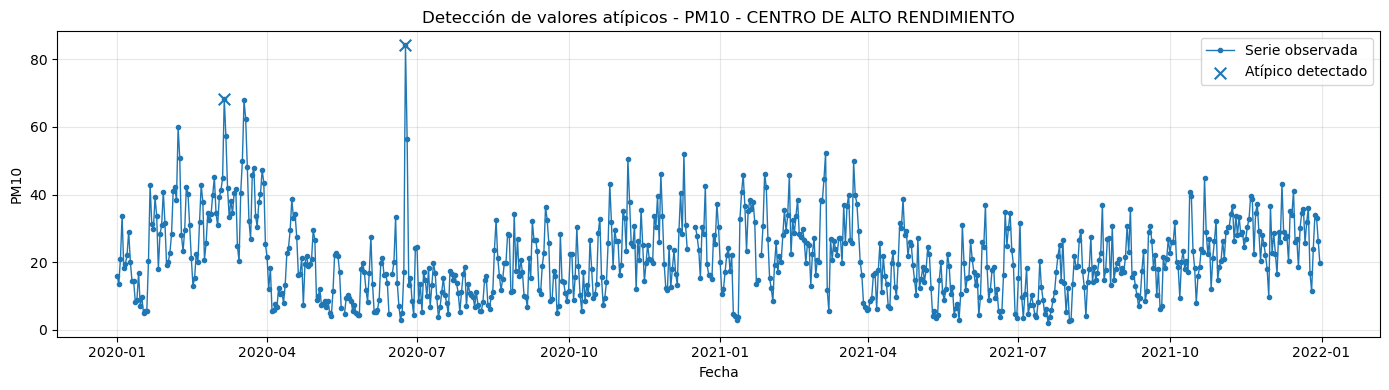

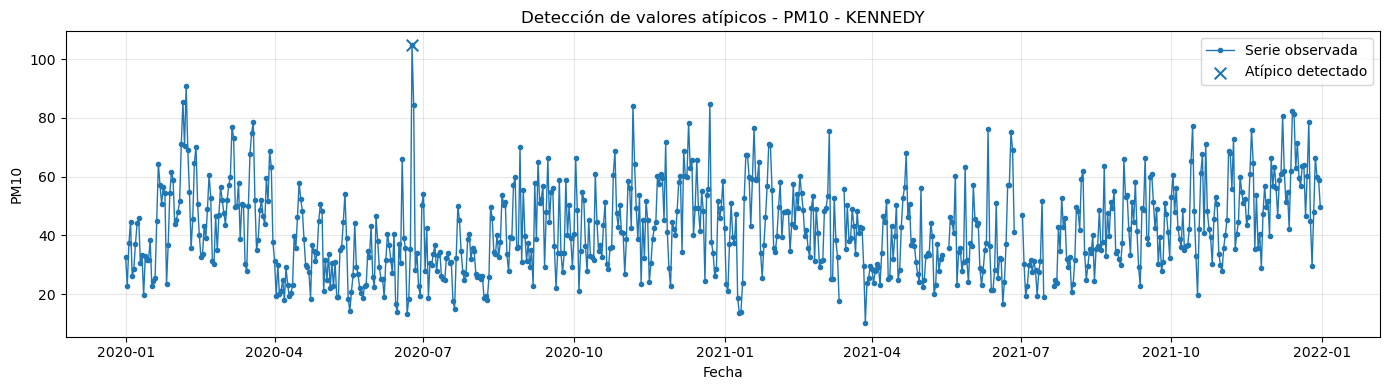

In [25]:
for estacion, sub in base.groupby("Estacion"):
    sub = sub.sort_values("Fecha inicial")
    out = sub[sub["Fue_atipico"]]

    plt.figure(figsize=(14, 4))
    plt.plot(sub["Fecha inicial"], sub[TARGET], marker="o", markersize=3, linewidth=1, label="Serie observada")

    if len(out) > 0:
        plt.scatter(out["Fecha inicial"], out[TARGET], s=70, marker="x", label="Atípico detectado")

    plt.title(f"Detección de valores atípicos - {TARGET} - {estacion}")
    plt.xlabel("Fecha")
    plt.ylabel(TARGET)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    nombre = f"atipicos_detectados_{TARGET}_{str(estacion).replace(' ', '_').replace('/', '_')}.png"
    plt.savefig(GRAF_DIR / nombre, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

## 6. Construcción de variables predictoras

In [26]:
def interpolar_por_estacion(df, col):
    return (
        df.groupby("Estacion", group_keys=False)[col]
        .apply(lambda s: s.interpolate(method="linear", limit_direction="both").bfill().ffill())
    )


def crear_features(df, columna_objetivo_modelo):
    """
    Crea variables predictoras para imputación.
    La columna objetivo original no se usa directamente como predictor actual.
    Se usan rezagos, medias móviles, covariables meteorológicas y calendario.
    """
    df = df.copy().sort_values(["Estacion", "Fecha inicial"])

    for cov in COVARIABLES:
        if cov in df.columns:
            df[cov] = pd.to_numeric(df[cov], errors="coerce")
            df[f"{cov}_interp"] = interpolar_por_estacion(df, cov)

    df["target_aux"] = interpolar_por_estacion(df, columna_objetivo_modelo)

    df["anio"] = df["Fecha inicial"].dt.year
    df["mes"] = df["Fecha inicial"].dt.month
    df["dia"] = df["Fecha inicial"].dt.day
    df["dia_semana"] = df["Fecha inicial"].dt.dayofweek
    df["es_fin_semana"] = (df["dia_semana"] >= 5).astype(int)
    df["dia_anio"] = df["Fecha inicial"].dt.dayofyear
    df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
    df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)
    df["dia_anio_sin"] = np.sin(2 * np.pi * df["dia_anio"] / 365)
    df["dia_anio_cos"] = np.cos(2 * np.pi * df["dia_anio"] / 365)

    if "DViento_interp" in df.columns:
        df["DViento_sin"] = np.sin(np.deg2rad(df["DViento_interp"]))
        df["DViento_cos"] = np.cos(np.deg2rad(df["DViento_interp"]))

    for lag in [1, 2, 3, 7, 14, 21, 30]:
        df[f"{TARGET}_lag_{lag}"] = df.groupby("Estacion")["target_aux"].shift(lag)

    for ventana in [3, 7, 14, 21, 30]:
        serie_pasada = df.groupby("Estacion")["target_aux"].shift(1)
        df[f"{TARGET}_media_{ventana}"] = serie_pasada.groupby(df["Estacion"]).rolling(ventana, min_periods=1).mean().reset_index(level=0, drop=True)
        df[f"{TARGET}_std_{ventana}"] = serie_pasada.groupby(df["Estacion"]).rolling(ventana, min_periods=2).std().reset_index(level=0, drop=True)
        df[f"{TARGET}_min_{ventana}"] = serie_pasada.groupby(df["Estacion"]).rolling(ventana, min_periods=1).min().reset_index(level=0, drop=True)
        df[f"{TARGET}_max_{ventana}"] = serie_pasada.groupby(df["Estacion"]).rolling(ventana, min_periods=1).max().reset_index(level=0, drop=True)

    df[f"{TARGET}_diff_1"] = df.groupby("Estacion")["target_aux"].shift(1) - df.groupby("Estacion")["target_aux"].shift(2)
    df[f"{TARGET}_diff_7"] = df.groupby("Estacion")["target_aux"].shift(1) - df.groupby("Estacion")["target_aux"].shift(7)

    for cov in COVARIABLES:
        c = f"{cov}_interp"
        if c in df.columns:
            for lag in [1, 2, 3, 7, 14]:
                df[f"{cov}_lag_{lag}"] = df.groupby("Estacion")[c].shift(lag)
            for ventana in [3, 7, 14]:
                serie_pasada = df.groupby("Estacion")[c].shift(1)
                df[f"{cov}_media_{ventana}"] = serie_pasada.groupby(df["Estacion"]).rolling(ventana, min_periods=1).mean().reset_index(level=0, drop=True)

    # Valor auxiliar de las otras estaciones en la misma fecha, si existe más de una estación.
    # Implementación vectorizada para evitar ciclos lentos cuando hay muchas estaciones.
    fecha_stats = (
        df.groupby("Fecha inicial")["target_aux"]
        .agg(suma_fecha="sum", conteo_fecha="count")
        .reset_index()
    )
    df = df.merge(fecha_stats, on="Fecha inicial", how="left")
    df[f"{TARGET}_otra_estacion_mismo_dia"] = (df["suma_fecha"] - df["target_aux"]) / (df["conteo_fecha"] - 1)
    df.loc[df["conteo_fecha"] <= 1, f"{TARGET}_otra_estacion_mismo_dia"] = np.nan
    df = df.drop(columns=["suma_fecha", "conteo_fecha"])

    dummies = pd.get_dummies(df["Estacion"], prefix="Estacion", dtype=int)
    df = pd.concat([df, dummies], axis=1)

    columnas_excluir = [
        "Estacion", "Fecha inicial", "Fecha final", TARGET, f"{TARGET}_original",
        f"{TARGET}_modelo", "target_aux", "Criterio_atipico"
    ]

    feature_cols = [
        c for c in df.columns
        if c not in columnas_excluir
        and pd.api.types.is_numeric_dtype(df[c])
        and c not in ["Fue_faltante_original", "Fue_atipico"]
    ]

    X = df[feature_cols].copy()
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median(numeric_only=True))
    X = X.fillna(0)

    return df, X, feature_cols


base_features, X_full, feature_cols = crear_features(base, f"{TARGET}_modelo")
base_features["Indice_original"] = base_features.index

print("Número de variables predictoras:", len(feature_cols))
display(pd.DataFrame({"Feature": feature_cols}).head(80))

Número de variables predictoras: 89


,Feature
0,DViento
1,VViento
2,HAire2
3,TAire2
4,Z_robusto_atipico
...,...
75,HAire2_media_3
76,HAire2_media_7
77,HAire2_media_14
78,TAire2_lag_1


## 7. Validación previa ocultando datos conocidos

In [27]:
def calcular_metricas(y_true, y_pred):
    y_true = pd.Series(y_true).astype(float)
    y_pred = pd.Series(y_pred, index=y_true.index).astype(float)
    data = pd.concat([y_true.rename("real"), y_pred.rename("pred")], axis=1).replace([np.inf, -np.inf], np.nan).dropna()

    if len(data) == 0:
        return {"MAE": np.nan, "RMSE": np.nan, "R2": np.nan, "MAPE_%": np.nan, "N": 0}

    mae = mean_absolute_error(data["real"], data["pred"])
    rmse = np.sqrt(mean_squared_error(data["real"], data["pred"]))
    r2 = r2_score(data["real"], data["pred"])

    mask = data["real"].abs() > 1e-9
    mape = np.mean(np.abs((data.loc[mask, "real"] - data.loc[mask, "pred"]) / data.loc[mask, "real"])) * 100 if mask.sum() > 0 else np.nan

    return {"MAE": mae, "RMSE": rmse, "R2": r2, "MAPE_%": mape, "N": len(data)}


conocidos_validos = base_features[base_features[f"{TARGET}_modelo"].notna()].copy()

n_validacion = int(len(conocidos_validos) * FRACCION_VALIDACION_OCULTA)
n_validacion = min(max(n_validacion, 10), MAX_REGISTROS_VALIDACION, len(conocidos_validos))

if n_validacion < 5:
    raise ValueError("No hay suficientes datos conocidos para hacer validación previa.")

idx_validacion = conocidos_validos.sample(n=n_validacion, random_state=SEED).index

base_validacion = base.copy()
y_validacion_real = base_validacion.loc[idx_validacion, f"{TARGET}_modelo"].copy()
base_validacion.loc[idx_validacion, f"{TARGET}_modelo"] = np.nan

base_val_features, X_val_full, feature_cols_val = crear_features(base_validacion, f"{TARGET}_modelo")

mask_train_val = base_val_features[f"{TARGET}_modelo"].notna()
mask_pred_val = base_val_features.index.isin(idx_validacion)

X_train_val = X_val_full.loc[mask_train_val, feature_cols_val]
y_train_val = base_val_features.loc[mask_train_val, f"{TARGET}_modelo"]
X_pred_val = X_val_full.loc[mask_pred_val, feature_cols_val]

if len(y_train_val) < MIN_DATOS_ENTRENAMIENTO:
    raise ValueError("No hay suficientes datos para entrenar la validación previa.")

modelo_validacion = RandomForestRegressor(
    n_estimators=250,
    max_depth=None,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features=0.8,
    bootstrap=True,
    random_state=SEED,
    n_jobs=-1,
    oob_score=True
)
modelo_validacion.fit(X_train_val, y_train_val)

pred_validacion = pd.Series(modelo_validacion.predict(X_pred_val), index=X_pred_val.index).clip(lower=0)
metricas_validacion = pd.DataFrame([calcular_metricas(y_validacion_real.loc[pred_validacion.index], pred_validacion)])
metricas_validacion["OOB_R2"] = getattr(modelo_validacion, "oob_score_", np.nan)
metricas_validacion["Registros_ocultados"] = len(pred_validacion)

predicciones_validacion = base_features.loc[pred_validacion.index, ["Estacion", "Fecha inicial"]].copy()
predicciones_validacion["Real_oculto"] = y_validacion_real.loc[pred_validacion.index].values
predicciones_validacion["Prediccion_RF"] = pred_validacion.values
predicciones_validacion["Error"] = predicciones_validacion["Real_oculto"] - predicciones_validacion["Prediccion_RF"]
predicciones_validacion["Error_abs"] = predicciones_validacion["Error"].abs()

print("Métricas de validación previa con datos ocultados:")
display(metricas_validacion)
display(predicciones_validacion.head(30))

Métricas de validación previa con datos ocultados:


,MAE,RMSE,R2,MAPE_%,N,OOB_R2,Registros_ocultados
0,1.991688,3.08661,0.967882,8.596595,120,0.966922,120


,Estacion,Fecha inicial,Real_oculto,Prediccion_RF,Error,Error_abs
15,CENTRO DE ALTO RENDIMIENTO,2020-01-16,9.683333,7.577389,2.105944,2.105944
29,CENTRO DE ALTO RENDIMIENTO,2020-01-30,31.595652,30.762166,0.833486,0.833486
44,CENTRO DE ALTO RENDIMIENTO,2020-02-14,30.991667,30.567925,0.423742,0.423742
49,CENTRO DE ALTO RENDIMIENTO,2020-02-19,20.120833,22.268682,-2.147849,2.147849
51,CENTRO DE ALTO RENDIMIENTO,2020-02-21,42.813043,44.540554,-1.727511,1.727511
66,CENTRO DE ALTO RENDIMIENTO,2020-03-07,57.262500,64.027530,-6.765030,6.765030
68,CENTRO DE ALTO RENDIMIENTO,2020-03-09,33.439130,28.533927,4.905203,4.905203
71,CENTRO DE ALTO RENDIMIENTO,2020-03-12,40.350000,38.998964,1.351036,1.351036
77,CENTRO DE ALTO RENDIMIENTO,2020-03-18,67.808333,65.267992,2.540341,2.540341
79,CENTRO DE ALTO RENDIMIENTO,2020-03-20,48.200000,48.953486,-0.753486,0.753486


## 8. Entrenamiento final e imputación de faltantes y atípicos

In [28]:
mask_train_final = base_features[f"{TARGET}_modelo"].notna()
mask_imputar = base_features[f"{TARGET}_modelo"].isna()

X_train = X_full.loc[mask_train_final, feature_cols]
y_train = base_features.loc[mask_train_final, f"{TARGET}_modelo"]
X_imputar = X_full.loc[mask_imputar, feature_cols]

if len(y_train) < MIN_DATOS_ENTRENAMIENTO:
    raise ValueError("No hay suficientes datos observados no atípicos para entrenar el modelo final.")

modelo_final = MODELO_RF
modelo_final.fit(X_train, y_train)

base_features[f"{TARGET}_final"] = base_features[f"{TARGET}_modelo"]
base_features["Fuente_valor"] = "Observado"
base_features.loc[base_features["Fue_faltante_original"], "Fuente_valor"] = "Faltante_original"
base_features.loc[base_features["Fue_atipico"], "Fuente_valor"] = "Atipico_detectado"

if len(X_imputar) > 0:
    pred_imputar = pd.Series(modelo_final.predict(X_imputar), index=X_imputar.index).clip(lower=0)
    base_features.loc[pred_imputar.index, f"{TARGET}_final"] = pred_imputar.values

    idx_falt = pred_imputar.index.intersection(base_features.index[base_features["Fue_faltante_original"]])
    idx_atip = pred_imputar.index.intersection(base_features.index[base_features["Fue_atipico"]])
    base_features.loc[idx_falt, "Fuente_valor"] = "Imputado_RF_faltante"
    base_features.loc[idx_atip, "Fuente_valor"] = "Imputado_RF_atipico"

faltantes_post_rf = base_features[f"{TARGET}_final"].isna()
if faltantes_post_rf.any():
    respaldo = interpolar_por_estacion(base_features, f"{TARGET}_final")
    base_features.loc[faltantes_post_rf, f"{TARGET}_final"] = respaldo.loc[faltantes_post_rf]
    base_features.loc[faltantes_post_rf, "Fuente_valor"] = "Imputado_interpolacion_respaldo"

base_features["Fue_imputado"] = base_features["Fuente_valor"].str.contains("Imputado", na=False)

solo_imputados = base_features[base_features["Fue_imputado"]].copy()
atipicos_imputados = base_features[base_features["Fue_atipico"]].copy()

print("OOB R² modelo final:", getattr(modelo_final, "oob_score_", np.nan))
print("Registros usados para entrenar:", len(y_train))
print("Registros imputados:", len(solo_imputados))
print("Atípicos imputados:", len(atipicos_imputados))

display(solo_imputados[["Estacion", "Fecha inicial", TARGET, f"{TARGET}_final", "Fue_faltante_original", "Fue_atipico", "Criterio_atipico", "Fuente_valor"]].head(50))

OOB R² modelo final: 0.9696063675404304
Registros usados para entrenar: 1438
Registros imputados: 24
Atípicos imputados: 3


,Estacion,Fecha inicial,PM10,PM10_final,Fue_faltante_original,Fue_atipico,Criterio_atipico,Fuente_valor
65,CENTRO DE ALTO RENDIMIENTO,2020-03-06,68.350000,64.945239,False,True,MAD_rolling+IQR,Imputado_RF_atipico
137,CENTRO DE ALTO RENDIMIENTO,2020-05-17,NaN,9.815571,True,False,,Imputado_RF_faltante
166,CENTRO DE ALTO RENDIMIENTO,2020-06-15,NaN,14.905691,True,False,,Imputado_RF_faltante
175,CENTRO DE ALTO RENDIMIENTO,2020-06-24,84.141667,31.751881,False,True,MAD_rolling+IQR,Imputado_RF_atipico
347,CENTRO DE ALTO RENDIMIENTO,2020-12-13,NaN,28.579980,True,False,,Imputado_RF_faltante
348,CENTRO DE ALTO RENDIMIENTO,2020-12-14,NaN,29.422511,True,False,,Imputado_RF_faltante
349,CENTRO DE ALTO RENDIMIENTO,2020-12-15,NaN,28.944886,True,False,,Imputado_RF_faltante
350,CENTRO DE ALTO RENDIMIENTO,2020-12-16,NaN,28.616236,True,False,,Imputado_RF_faltante
390,CENTRO DE ALTO RENDIMIENTO,2021-01-25,NaN,29.140325,True,False,,Imputado_RF_faltante
906,KENNEDY,2020-06-24,104.741667,67.526666,False,True,MAD_rolling+IQR,Imputado_RF_atipico


## 9. Importancia de variables

Importancia de variables:


,Variable_predictora,Importancia
0,Mediana_rolling_atipico,0.509535
1,Z_robusto_atipico,0.294844
2,PM10_lag_1,0.061366
3,PM10_otra_estacion_mismo_dia,0.035047
4,PM10_media_7,0.021313
5,PM10_media_21,0.010010
6,PM10_media_14,0.007084
7,PM10_media_30,0.006592
8,MAD_rolling_atipico,0.004239
9,PM10_max_14,0.002109


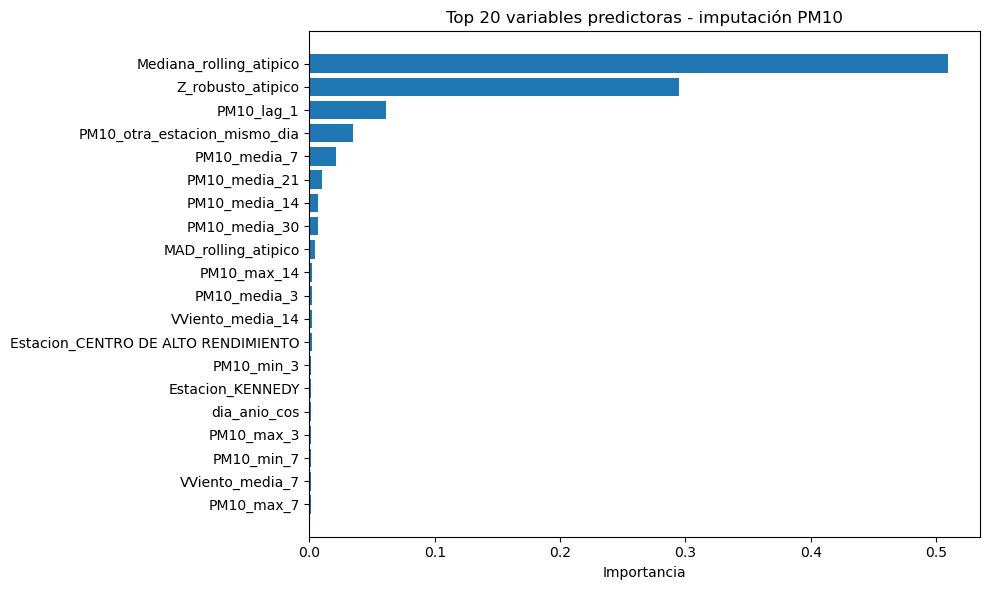

In [29]:
importancia_variables = pd.DataFrame({
    "Variable_predictora": feature_cols,
    "Importancia": modelo_final.feature_importances_
}).sort_values("Importancia", ascending=False).reset_index(drop=True)

print("Importancia de variables:")
display(importancia_variables.head(30))

plt.figure(figsize=(10, 6))
top_imp = importancia_variables.head(20).sort_values("Importancia")
plt.barh(top_imp["Variable_predictora"], top_imp["Importancia"])
plt.title(f"Top 20 variables predictoras - imputación {TARGET}")
plt.xlabel("Importancia")
plt.tight_layout()
plt.savefig(GRAF_DIR / f"importancia_variables_{TARGET}.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

## 10. Comparación antes y después de imputar

In [30]:
def describir_serie(s):
    return pd.Series({
        "n": s.notna().sum(),
        "media": s.mean(),
        "std": s.std(),
        "min": s.min(),
        "p25": s.quantile(0.25),
        "mediana": s.median(),
        "p75": s.quantile(0.75),
        "max": s.max(),
    })

estadisticos_antes = base_features.groupby("Estacion")[f"{TARGET}_original"].apply(describir_serie).unstack().reset_index()
estadisticos_modelo = base_features.groupby("Estacion")[f"{TARGET}_modelo"].apply(describir_serie).unstack().reset_index()
estadisticos_despues = base_features.groupby("Estacion")[f"{TARGET}_final"].apply(describir_serie).unstack().reset_index()

print("Estadísticos antes de tratar faltantes y atípicos:")
display(estadisticos_antes)

print("Estadísticos después de retirar atípicos para entrenamiento:")
display(estadisticos_modelo)

print("Estadísticos después de imputar faltantes y atípicos:")
display(estadisticos_despues)

Estadísticos antes de tratar faltantes y atípicos:


,Estacion,n,media,std,min,p25,mediana,p75,max
0,CENTRO DE ALTO RENDIMIENTO,724.0,21.250527,11.705476,2.1125,12.150198,19.910417,28.356839,84.141667
1,KENNEDY,717.0,42.018122,14.916974,10.2400,30.954167,39.916667,51.641667,104.741667


Estadísticos después de retirar atípicos para entrenamiento:


,Estacion,n,media,std,min,p25,mediana,p75,max
0,CENTRO DE ALTO RENDIMIENTO,722.0,21.098185,11.349554,2.1125,12.105138,19.895265,28.316761,67.808333
1,KENNEDY,716.0,41.930519,14.741682,10.2400,30.951042,39.912500,51.616667,90.891667


Estadísticos después de imputar faltantes y atípicos:


,Estacion,n,media,std,min,p25,mediana,p75,max
0,CENTRO DE ALTO RENDIMIENTO,731.0,21.202479,11.430284,2.1125,12.177668,19.923810,28.502083,67.808333
1,KENNEDY,731.0,41.821214,14.675841,10.2400,30.947917,39.804167,51.472917,90.891667


## 11. Gráficas finales por estación

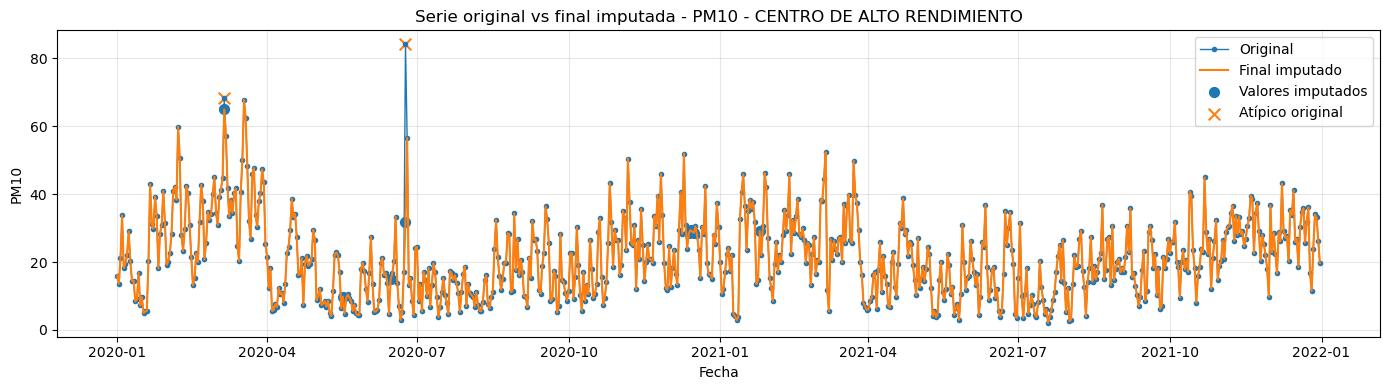

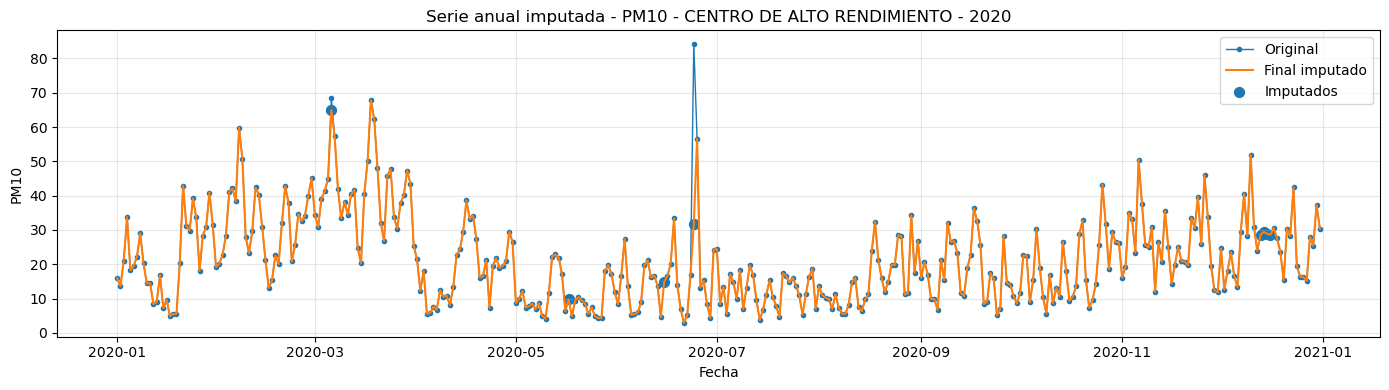

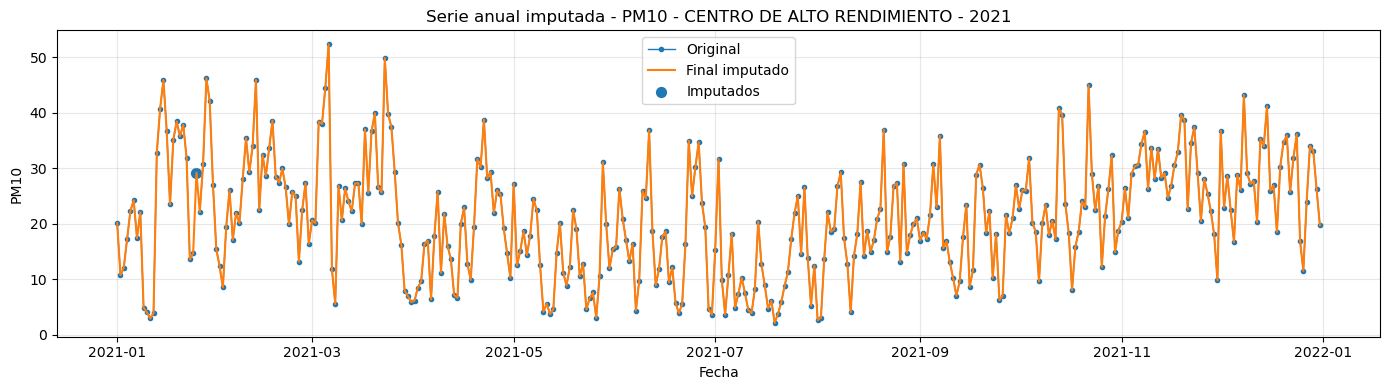

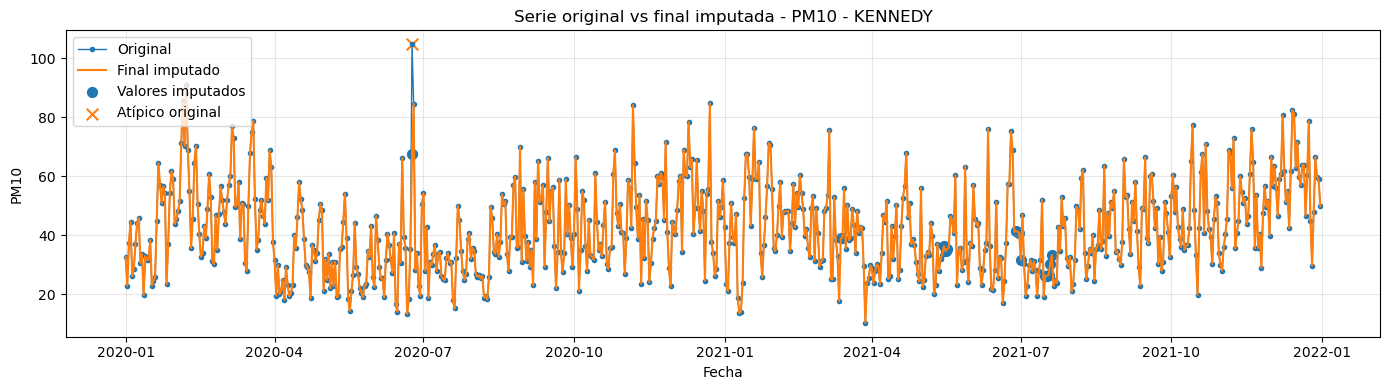

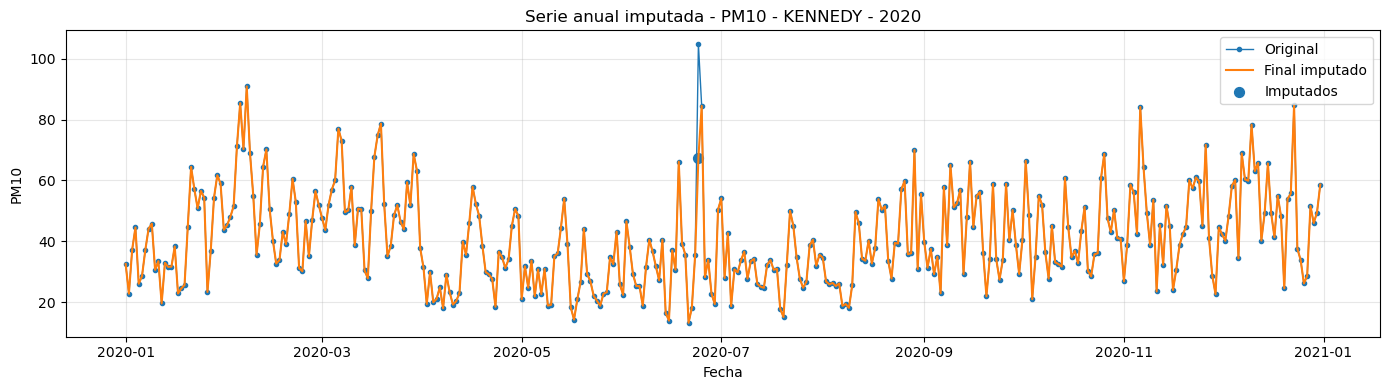

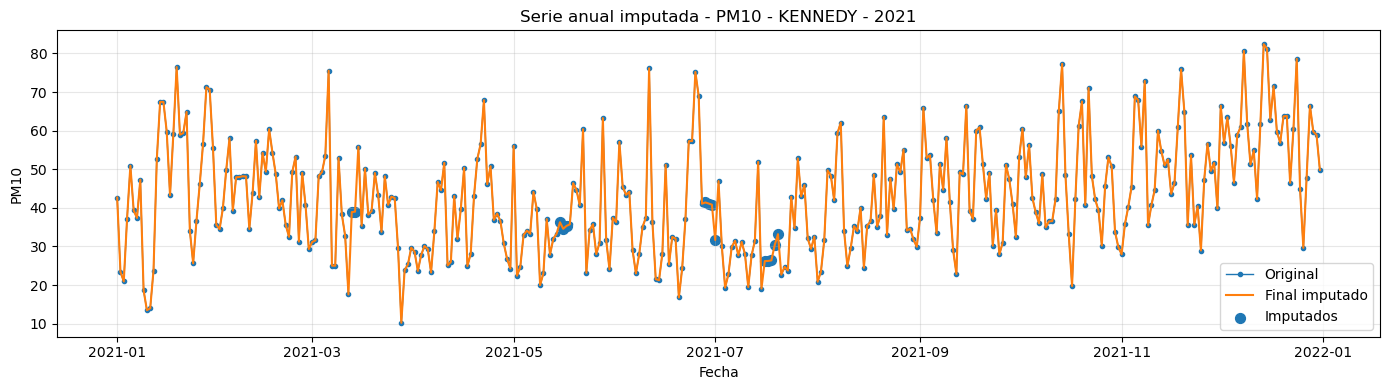

In [31]:
for estacion, sub in base_features.groupby("Estacion"):
    sub = sub.sort_values("Fecha inicial")
    imput = sub[sub["Fue_imputado"]]
    out = sub[sub["Fue_atipico"]]

    plt.figure(figsize=(14, 4))
    plt.plot(sub["Fecha inicial"], sub[f"{TARGET}_original"], marker="o", markersize=3, linewidth=1, label="Original")
    plt.plot(sub["Fecha inicial"], sub[f"{TARGET}_final"], linewidth=1.5, label="Final imputado")

    if len(imput) > 0:
        plt.scatter(imput["Fecha inicial"], imput[f"{TARGET}_final"], s=50, label="Valores imputados")

    if len(out) > 0:
        plt.scatter(out["Fecha inicial"], out[TARGET], s=70, marker="x", label="Atípico original")

    plt.title(f"Serie original vs final imputada - {TARGET} - {estacion}")
    plt.xlabel("Fecha")
    plt.ylabel(TARGET)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    nombre = f"serie_original_vs_imputada_{TARGET}_{str(estacion).replace(' ', '_').replace('/', '_')}.png"
    plt.savefig(GRAF_DIR / nombre, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

    for anio, sub_anio in sub.groupby(sub["Fecha inicial"].dt.year):
        plt.figure(figsize=(14, 4))
        plt.plot(sub_anio["Fecha inicial"], sub_anio[f"{TARGET}_original"], marker="o", markersize=3, linewidth=1, label="Original")
        plt.plot(sub_anio["Fecha inicial"], sub_anio[f"{TARGET}_final"], linewidth=1.5, label="Final imputado")
        imput_anio = sub_anio[sub_anio["Fue_imputado"]]
        if len(imput_anio) > 0:
            plt.scatter(imput_anio["Fecha inicial"], imput_anio[f"{TARGET}_final"], s=50, label="Imputados")
        plt.title(f"Serie anual imputada - {TARGET} - {estacion} - {anio}")
        plt.xlabel("Fecha")
        plt.ylabel(TARGET)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        nombre = f"serie_anual_{TARGET}_{str(estacion).replace(' ', '_').replace('/', '_')}_{anio}.png"
        plt.savefig(GRAF_DIR / nombre, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()

## 12. Exportación de resultados

In [32]:
# ============================================================
# EXPORTACIÓN COMPLETA DEL DATASET FINAL IMPUTADO
# ============================================================

# 1. Detalle técnico completo: conserva columnas originales, valor modelo, valor final y banderas.
columnas_detalle = [
    "Estacion", "Fecha inicial", "Fecha final",
    f"{TARGET}_original", TARGET, f"{TARGET}_modelo", f"{TARGET}_final",
    "Fue_faltante_original", "Fue_atipico", "Criterio_atipico",
    "Z_robusto_atipico", "Mediana_rolling_atipico", "MAD_rolling_atipico",
    "Limite_IQR_inferior", "Limite_IQR_superior",
    "Fue_imputado", "Fuente_valor"
]

# Agregar covariables meteorológicas originales al detalle.
for cov in COVARIABLES:
    if cov in base_features.columns and cov not in columnas_detalle:
        columnas_detalle.append(cov)

columnas_detalle = [c for c in columnas_detalle if c in base_features.columns]
detalle = base_features[columnas_detalle].copy()

# 2. Dataset final limpio: este es el archivo principal para seguir trabajando.
# Contiene la variable objetivo ya corregida: faltantes + atípicos imputados.
columnas_dataset_final = ["Estacion", "Fecha inicial", "Fecha final"]

for cov in COVARIABLES:
    if cov in base_features.columns and cov not in columnas_dataset_final:
        columnas_dataset_final.append(cov)

dataset_final = base_features[columnas_dataset_final].copy()
dataset_final[TARGET] = base_features[f"{TARGET}_final"].values

# Orden recomendado: Estacion, fechas, TARGET y luego covariables.
cols_ordenadas = ["Estacion", "Fecha inicial", "Fecha final", TARGET]
cols_ordenadas += [c for c in dataset_final.columns if c not in cols_ordenadas]
dataset_final = dataset_final[cols_ordenadas].copy()

# 3. Dataset final con trazabilidad: igual al final, pero añade banderas para saber qué fue imputado.
dataset_final_trazabilidad = dataset_final.copy()
dataset_final_trazabilidad[f"{TARGET}_original"] = base_features[f"{TARGET}_original"].values
dataset_final_trazabilidad["Fuente_valor"] = base_features["Fuente_valor"].values
dataset_final_trazabilidad["Fue_imputado"] = base_features["Fue_imputado"].values
dataset_final_trazabilidad["Fue_faltante_original"] = base_features["Fue_faltante_original"].values
dataset_final_trazabilidad["Fue_atipico"] = base_features["Fue_atipico"].values
dataset_final_trazabilidad["Criterio_atipico"] = base_features["Criterio_atipico"].values

# 4. Tabla exclusiva de valores imputados.
tabla_imputados = solo_imputados[[
    c for c in [
        "Estacion", "Fecha inicial", "Fecha final",
        TARGET, f"{TARGET}_original", f"{TARGET}_modelo", f"{TARGET}_final",
        "Fuente_valor", "Fue_faltante_original", "Fue_atipico", "Criterio_atipico"
    ]
    if c in solo_imputados.columns
]].copy()

if f"{TARGET}_final" in tabla_imputados.columns:
    tabla_imputados = tabla_imputados.rename(columns={f"{TARGET}_final": f"{TARGET}_imputado"})

# 5. Tabla de atípicos detectados.
tabla_atipicos = base_features[base_features["Fue_atipico"]][columnas_detalle].copy()

# 6. Rutas de exportación.
path_detalle = TABLAS_DIR / f"{TARGET}_dataset_completo_imputado_detallado_RF_atipicos.csv"
path_final = TABLAS_DIR / f"{TARGET}_dataset_final_imputado_RF_atipicos.csv"
path_final_xlsx = TABLAS_DIR / f"{TARGET}_dataset_final_imputado_RF_atipicos.xlsx"
path_final_trazabilidad = TABLAS_DIR / f"{TARGET}_dataset_final_imputado_con_trazabilidad_RF_atipicos.csv"
path_final_trazabilidad_xlsx = TABLAS_DIR / f"{TARGET}_dataset_final_imputado_con_trazabilidad_RF_atipicos.xlsx"

# Nombre adicional compatible con versiones anteriores.
path_final_compatibilidad = TABLAS_DIR / f"{TARGET}_dataset_completo_final_RF_atipicos.csv"

path_imputados = TABLAS_DIR / f"{TARGET}_valores_imputados_RF_atipicos.csv"
path_atipicos = TABLAS_DIR / f"{TARGET}_atipicos_detectados_RF.csv"
path_metricas = TABLAS_DIR / f"{TARGET}_validacion_metricas_RF_atipicos.csv"
path_pred_val = TABLAS_DIR / f"{TARGET}_validacion_predicciones_RF_atipicos.csv"
path_importancia = TABLAS_DIR / f"{TARGET}_importancia_variables_RF_atipicos.csv"
path_resumen = TABLAS_DIR / f"{TARGET}_resumen_faltantes_atipicos.csv"
path_est_antes = TABLAS_DIR / f"{TARGET}_estadisticos_antes.csv"
path_est_modelo = TABLAS_DIR / f"{TARGET}_estadisticos_sin_atipicos_para_entrenar.csv"
path_est_despues = TABLAS_DIR / f"{TARGET}_estadisticos_despues_imputacion.csv"

# 7. Exportar CSV.
detalle.to_csv(path_detalle, index=False, encoding="utf-8-sig")
dataset_final.to_csv(path_final, index=False, encoding="utf-8-sig")
dataset_final.to_csv(path_final_compatibilidad, index=False, encoding="utf-8-sig")
dataset_final_trazabilidad.to_csv(path_final_trazabilidad, index=False, encoding="utf-8-sig")
tabla_imputados.to_csv(path_imputados, index=False, encoding="utf-8-sig")
tabla_atipicos.to_csv(path_atipicos, index=False, encoding="utf-8-sig")
metricas_validacion.to_csv(path_metricas, index=False, encoding="utf-8-sig")
predicciones_validacion.to_csv(path_pred_val, index=False, encoding="utf-8-sig")
importancia_variables.to_csv(path_importancia, index=False, encoding="utf-8-sig")
resumen_atipicos.to_csv(path_resumen, index=False, encoding="utf-8-sig")
estadisticos_antes.to_csv(path_est_antes, index=False, encoding="utf-8-sig")
estadisticos_modelo.to_csv(path_est_modelo, index=False, encoding="utf-8-sig")
estadisticos_despues.to_csv(path_est_despues, index=False, encoding="utf-8-sig")

# 8. Exportar Excel individuales del dataset final.
dataset_final.to_excel(path_final_xlsx, index=False)
dataset_final_trazabilidad.to_excel(path_final_trazabilidad_xlsx, index=False)

# 9. Exportar resumen general en Excel.
path_excel = OUTPUT_DIR / f"{TARGET}_imputacion_RF_con_atipicos_resumen.xlsx"

with pd.ExcelWriter(path_excel, engine="openpyxl") as writer:
    dataset_final.to_excel(writer, sheet_name="DATASET_FINAL", index=False)
    dataset_final_trazabilidad.to_excel(writer, sheet_name="final_con_trazabilidad", index=False)
    detalle.to_excel(writer, sheet_name="detalle_completo", index=False)
    tabla_imputados.to_excel(writer, sheet_name="solo_imputados", index=False)
    tabla_atipicos.to_excel(writer, sheet_name="atipicos_detectados", index=False)
    resumen_atipicos.to_excel(writer, sheet_name="resumen_falt_atipicos", index=False)
    metricas_validacion.to_excel(writer, sheet_name="metricas_validacion", index=False)
    predicciones_validacion.to_excel(writer, sheet_name="pred_validacion", index=False)
    importancia_variables.to_excel(writer, sheet_name="importancia_variables", index=False)
    estadisticos_antes.to_excel(writer, sheet_name="estadisticos_antes", index=False)
    estadisticos_modelo.to_excel(writer, sheet_name="sin_atipicos_entrenar", index=False)
    estadisticos_despues.to_excel(writer, sheet_name="estadisticos_despues", index=False)

# 10. Resumen de control.
control_exportacion = pd.DataFrame([{
    "Target": TARGET,
    "Total_registros_dataset_final": len(dataset_final),
    "Total_estaciones": dataset_final["Estacion"].nunique() if "Estacion" in dataset_final.columns else np.nan,
    "Fecha_minima": dataset_final["Fecha inicial"].min(),
    "Fecha_maxima": dataset_final["Fecha inicial"].max(),
    "Total_valores_finales_nulos": dataset_final[TARGET].isna().sum(),
    "Total_imputados": int(base_features["Fue_imputado"].sum()),
    "Total_faltantes_originales": int(base_features["Fue_faltante_original"].sum()),
    "Total_atipicos_imputados": int(base_features["Fue_atipico"].sum())
}])

display(Markdown("## Control de exportación del dataset final imputado"))
display(control_exportacion)

print("Exportación finalizada correctamente.")
print("Carpeta de salida:", OUTPUT_DIR.resolve())
print("Dataset final limpio CSV:", path_final.resolve())
print("Dataset final limpio Excel:", path_final_xlsx.resolve())
print("Dataset final con trazabilidad CSV:", path_final_trazabilidad.resolve())
print("Dataset final con trazabilidad Excel:", path_final_trazabilidad_xlsx.resolve())
print("Excel resumen:", path_excel.resolve())

## Control de exportación del dataset final imputado

,Target,Total_registros_dataset_final,Total_estaciones,Fecha_minima,Fecha_maxima,Total_valores_finales_nulos,Total_imputados,Total_faltantes_originales,Total_atipicos_imputados
0,PM10,1462,2,2020-01-01,2021-12-31,0,24,21,3


Exportación finalizada correctamente.
Carpeta de salida: C:\Users\santi\Bogota_Version_2\salidas_PM10_RF_con_atipicos
Dataset final limpio CSV: C:\Users\santi\Bogota_Version_2\salidas_PM10_RF_con_atipicos\tablas\PM10_dataset_final_imputado_RF_atipicos.csv
Dataset final limpio Excel: C:\Users\santi\Bogota_Version_2\salidas_PM10_RF_con_atipicos\tablas\PM10_dataset_final_imputado_RF_atipicos.xlsx
Dataset final con trazabilidad CSV: C:\Users\santi\Bogota_Version_2\salidas_PM10_RF_con_atipicos\tablas\PM10_dataset_final_imputado_con_trazabilidad_RF_atipicos.csv
Dataset final con trazabilidad Excel: C:\Users\santi\Bogota_Version_2\salidas_PM10_RF_con_atipicos\tablas\PM10_dataset_final_imputado_con_trazabilidad_RF_atipicos.xlsx
Excel resumen: C:\Users\santi\Bogota_Version_2\salidas_PM10_RF_con_atipicos\PM10_imputacion_RF_con_atipicos_resumen.xlsx


## 13. Texto metodológico para el documento

In [33]:
texto_metodologico = f"""
Para el tratamiento de faltantes y valores atípicos de {TARGET}, se construyó una serie diaria completa por estación. Inicialmente se identificaron los valores faltantes originales y, posteriormente, se aplicó una detección de atípicos mediante un criterio robusto basado en mediana móvil y desviación absoluta mediana (MAD), complementado con el criterio del rango intercuartílico (IQR) por estación. Los valores negativos se consideraron inválidos automáticamente. Para evitar eliminar picos reales de contaminación, la configuración por defecto marcó como atípico un dato cuando cumplía simultáneamente los criterios MAD e IQR, además de los casos negativos.

Los valores faltantes y los valores atípicos detectados fueron tratados como datos a imputar. Para la imputación se empleó un modelo Random Forest multivariable, incorporando covariables meteorológicas, variables calendario, rezagos del contaminante, medias móviles y, cuando existían varias estaciones, información auxiliar de la otra estación en la misma fecha. Antes de la imputación final se realizó una validación previa ocultando una fracción de datos observados, con el fin de estimar el desempeño del modelo mediante MAE, RMSE, MAPE y R². Finalmente, el modelo se entrenó con todos los datos válidos no atípicos y se imputaron tanto los faltantes como los valores atípicos detectados.
"""

display(Markdown(texto_metodologico))


Para el tratamiento de faltantes y valores atípicos de PM10, se construyó una serie diaria completa por estación. Inicialmente se identificaron los valores faltantes originales y, posteriormente, se aplicó una detección de atípicos mediante un criterio robusto basado en mediana móvil y desviación absoluta mediana (MAD), complementado con el criterio del rango intercuartílico (IQR) por estación. Los valores negativos se consideraron inválidos automáticamente. Para evitar eliminar picos reales de contaminación, la configuración por defecto marcó como atípico un dato cuando cumplía simultáneamente los criterios MAD e IQR, además de los casos negativos.

Los valores faltantes y los valores atípicos detectados fueron tratados como datos a imputar. Para la imputación se empleó un modelo Random Forest multivariable, incorporando covariables meteorológicas, variables calendario, rezagos del contaminante, medias móviles y, cuando existían varias estaciones, información auxiliar de la otra estación en la misma fecha. Antes de la imputación final se realizó una validación previa ocultando una fracción de datos observados, con el fin de estimar el desempeño del modelo mediante MAE, RMSE, MAPE y R². Finalmente, el modelo se entrenó con todos los datos válidos no atípicos y se imputaron tanto los faltantes como los valores atípicos detectados.


In [34]:
# ============================================================
# GUARDAR CSV FINAL EN LA CARPETA PRINCIPAL DEL JUPYTER
# ============================================================

from pathlib import Path
import pandas as pd

# Esta celda deja una copia del dataset final directamente en la carpeta
# donde se está ejecutando el notebook, no solamente dentro de la carpeta "salidas...".

if "dataset_final" not in globals():
    raise NameError(
        "No existe la variable 'dataset_final'. "
        "Ejecuta primero todo el notebook hasta la celda de exportación."
    )

if "TARGET" in globals():
    nombre_variable_final = str(TARGET).replace(".", "")
elif "VARIABLE" in globals():
    nombre_variable_final = str(VARIABLE).replace(".", "")
else:
    nombre_variable_final = "variable"

carpeta_jupyter = Path.cwd()

archivo_csv_final = carpeta_jupyter / f"{nombre_variable_final}_DATASET_FINAL_IMPUTADO.csv"
dataset_final.to_csv(archivo_csv_final, index=False, encoding="utf-8-sig")

print("CSV final guardado correctamente en la carpeta principal del Jupyter:")
print(archivo_csv_final.resolve())

# Opcional: también se guarda una copia con trazabilidad, si existe.
if "dataset_final_trazabilidad" in globals():
    archivo_csv_trazabilidad = carpeta_jupyter / f"{nombre_variable_final}_DATASET_FINAL_IMPUTADO_CON_TRAZABILIDAD.csv"
    dataset_final_trazabilidad.to_csv(archivo_csv_trazabilidad, index=False, encoding="utf-8-sig")

    print("CSV final con trazabilidad guardado correctamente:")
    print(archivo_csv_trazabilidad.resolve())

display(dataset_final.head())

CSV final guardado correctamente en la carpeta principal del Jupyter:
C:\Users\santi\Bogota_Version_2\PM10_DATASET_FINAL_IMPUTADO.csv
CSV final con trazabilidad guardado correctamente:
C:\Users\santi\Bogota_Version_2\PM10_DATASET_FINAL_IMPUTADO_CON_TRAZABILIDAD.csv


,Estacion,Fecha inicial,Fecha final,PM10,DViento,VViento,HAire2,TAire2
0,CENTRO DE ALTO RENDIMIENTO,2020-01-01,2020-01-01,16.031579,251.333333,1.679167,70.125000,16.129167
1,CENTRO DE ALTO RENDIMIENTO,2020-01-02,2020-01-02,13.608696,273.625000,1.758333,67.041667,16.650000
2,CENTRO DE ALTO RENDIMIENTO,2020-01-03,2020-01-03,21.104348,255.875000,1.429167,66.833333,15.733333
3,CENTRO DE ALTO RENDIMIENTO,2020-01-04,2020-01-04,33.739130,298.958333,1.666667,66.041667,15.037500
4,CENTRO DE ALTO RENDIMIENTO,2020-01-05,2020-01-05,18.272727,260.500000,1.758333,68.083333,14.533333


In [35]:
# ============================================================
# TIEMPO TOTAL DE EJECUCIÓN DEL NOTEBOOK
# ============================================================

import time
from datetime import datetime
from pathlib import Path
import pandas as pd

if "TIEMPO_INICIO_NOTEBOOK" not in globals():
    raise NameError(
        "No existe TIEMPO_INICIO_NOTEBOOK. "
        "Ejecuta el notebook desde la primera celda para medir correctamente el tiempo total."
    )

TIEMPO_FIN_NOTEBOOK = time.perf_counter()
FECHA_HORA_FIN_NOTEBOOK = datetime.now()

TIEMPO_TOTAL_SEGUNDOS = TIEMPO_FIN_NOTEBOOK - TIEMPO_INICIO_NOTEBOOK
TIEMPO_TOTAL_MINUTOS = TIEMPO_TOTAL_SEGUNDOS / 60
TIEMPO_TOTAL_HORAS = TIEMPO_TOTAL_MINUTOS / 60

if "TARGET" in globals():
    nombre_variable_tiempo = str(TARGET).replace(".", "")
elif "VARIABLE" in globals():
    nombre_variable_tiempo = str(VARIABLE).replace(".", "")
else:
    nombre_variable_tiempo = "variable"

tiempo_ejecucion_df = pd.DataFrame([{
    "Variable": nombre_variable_tiempo,
    "Fecha_hora_inicio": FECHA_HORA_INICIO_NOTEBOOK,
    "Fecha_hora_fin": FECHA_HORA_FIN_NOTEBOOK,
    "Tiempo_total_segundos": round(TIEMPO_TOTAL_SEGUNDOS, 4),
    "Tiempo_total_minutos": round(TIEMPO_TOTAL_MINUTOS, 4),
    "Tiempo_total_horas": round(TIEMPO_TOTAL_HORAS, 4)
}])

display(tiempo_ejecucion_df)

carpeta_jupyter = Path.cwd()
archivo_tiempo_jupyter = carpeta_jupyter / f"{nombre_variable_tiempo}_TIEMPO_EJECUCION_NOTEBOOK.csv"
tiempo_ejecucion_df.to_csv(archivo_tiempo_jupyter, index=False, encoding="utf-8-sig")

print("Tiempo total de ejecución del notebook:")
print(f"{TIEMPO_TOTAL_SEGUNDOS:.2f} segundos")
print(f"{TIEMPO_TOTAL_MINUTOS:.2f} minutos")
print("Archivo de tiempo guardado en la carpeta principal del Jupyter:")
print(archivo_tiempo_jupyter.resolve())

# También se guarda dentro de la carpeta de salidas, si existe.
if "TABLAS_DIR" in globals():
    archivo_tiempo_salidas = TABLAS_DIR / f"{nombre_variable_tiempo}_tiempo_total_ejecucion_notebook.csv"
    tiempo_ejecucion_df.to_csv(archivo_tiempo_salidas, index=False, encoding="utf-8-sig")
    print("Archivo de tiempo guardado también en la carpeta de tablas:")
    print(archivo_tiempo_salidas.resolve())

,Variable,Fecha_hora_inicio,Fecha_hora_fin,Tiempo_total_segundos,Tiempo_total_minutos,Tiempo_total_horas
0,PM10,2026-07-10 21:39:43.573521,2026-07-10 21:40:25.975490,42.4022,0.7067,0.0118


Tiempo total de ejecución del notebook:
42.40 segundos
0.71 minutos
Archivo de tiempo guardado en la carpeta principal del Jupyter:
C:\Users\santi\Bogota_Version_2\PM10_TIEMPO_EJECUCION_NOTEBOOK.csv
Archivo de tiempo guardado también en la carpeta de tablas:
C:\Users\santi\Bogota_Version_2\salidas_PM10_RF_con_atipicos\tablas\PM10_tiempo_total_ejecucion_notebook.csv
